# Falcon 9 Landing Classification

## tl;dr
Compare four classifiers using training-only preprocessing and cross-validation. Select a model before evaluating its held-out test set, and compare with a majority-class baseline.

## Context & Methods
IBM course project, reproduced from attributed historical snapshots. See `data/source_manifest.json` for URLs and hashes.

### Key Assumptions
Course success labels include controlled ocean landings; descriptive associations are not causal effects.

## Data
Run from a clean kernel. All ordinary analysis uses included source snapshots.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'falcon9').exists() else Path.cwd().parent
if not (ROOT / 'falcon9').exists():
    raise RuntimeError('Start Jupyter in the repository root or notebooks directory')
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from falcon9.analysis import load_data, group_summary
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
df = load_data()


### Modeling contract
Predictors: flight sequence, prior flight count, block, orbit, site, grid fins, reused status, legs. Exclude upstream-imputed payload, cumulative ReusedCount, outcome-derived columns and serial/landing identifiers. Random splitting is the main educational comparison; a separate chronological split is a sensitivity check. Neither is production validation.

In [2]:
from falcon9.analysis import FEATURES, run_experiment
display(df[FEATURES].head())
print('Target counts:', df.Class.value_counts().to_dict())

Target counts: {1: 60, 0: 30}


,FlightNumber,Flights,Block,Orbit,LaunchSite,GridFins,Reused,Legs
0,1,1,1.0,LEO,CCAFS SLC 40,False,False,False
1,2,1,1.0,LEO,CCAFS SLC 40,False,False,False
2,3,1,1.0,ISS,CCAFS SLC 40,False,False,False
3,4,1,1.0,PO,VAFB SLC 4E,False,False,False
4,5,1,1.0,GTO,CCAFS SLC 40,False,False,False


## Results
### Train, tune, select, then evaluate
Each classifier has a full preprocessing pipeline fitted inside five-fold training CV. Selection uses CV balanced accuracy. Only the selected model and the baseline are scored on each held-out set.

In [3]:
random_result, random_predictions = run_experiment(df)
comparison = pd.DataFrame(random_result['cv_comparison'])
display(comparison[['model','cv_balanced_accuracy','cv_std','parameters']])
print('Selected:', random_result['selected_model'])
display(pd.DataFrame({'Selected': random_result['selected_test'], 'Baseline': random_result['baseline_test']}).drop(index='confusion_matrix'))

Selected: SVM


,model,cv_balanced_accuracy,cv_std,parameters
0,SVM,0.835000,0.099499,"{'model__C': 1, 'model__kernel': 'rbf'}"
1,KNN,0.833889,0.096807,"{'model__n_neighbors': 3, 'model__weights': 'd..."
2,Decision tree,0.823889,0.080308,"{'model__max_depth': 2, 'model__min_samples_le..."
3,Logistic regression,0.805000,0.095394,{'model__C': 1}


,Selected,Baseline
accuracy,0.777778,0.666667
balanced_accuracy,0.666667,0.5
precision,0.75,0.666667
recall,1.0,1.0
f1,0.857143,0.8


### Cross-validation comparison
Error bars show fold-score standard deviation, not confidence intervals.

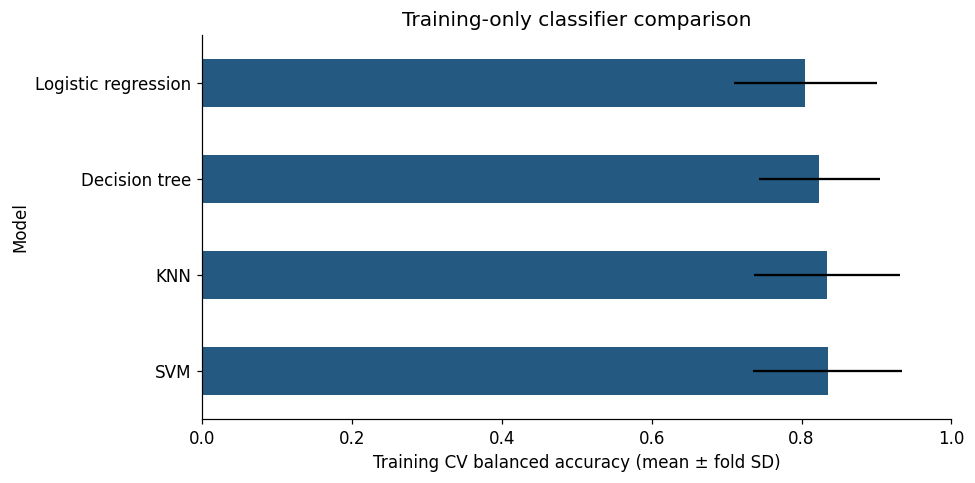

In [4]:
ax = comparison.plot.barh(x='model', y='cv_balanced_accuracy', xerr='cv_std', color='#245a81', legend=False)
ax.set(xlim=(0,1), xlabel='Training CV balanced accuracy (mean ± fold SD)', ylabel='Model', title='Training-only classifier comparison')
plt.tight_layout(); plt.show()

### Held-out confusion matrix and individual errors

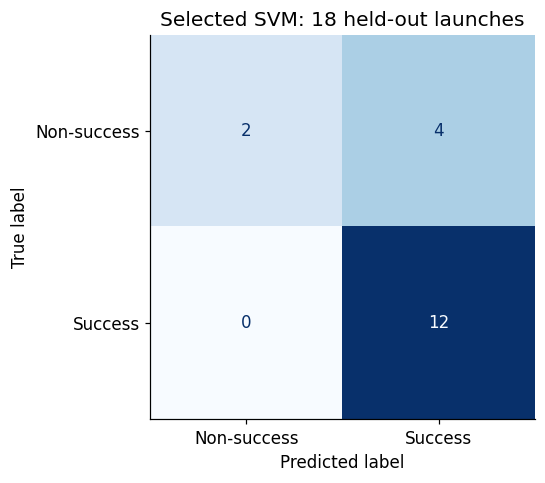

,FlightNumber,actual,prediction
0,33,1,1
1,46,0,1
2,10,0,0
3,14,0,1
4,22,1,1
5,34,1,1
6,47,0,1
7,69,1,1
8,81,1,1
9,63,1,1


In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(__import__('numpy').array(random_result['selected_test']['confusion_matrix']), display_labels=['Non-success','Success']).plot(cmap='Blues', colorbar=False)
plt.title(f"Selected {random_result['selected_model']}: {random_result['test_n']} held-out launches")
plt.tight_layout(); plt.show()
display(random_predictions)

### Chronological sensitivity
Train on the first 80% of launches, evaluate the last 20%. Training-only CV is stratified and shuffled, not rolling-origin forecasting. Report the temporal test class distribution because class imbalance changes interpretation.

In [6]:
temporal_result, temporal_predictions = run_experiment(df, temporal=True)
print('Temporal test classes:', temporal_result['test_class_counts'])
display(pd.DataFrame([{'split': r['split'], 'selected': r['selected_model'], 'test_n': r['test_n'], 'accuracy': r['selected_test']['accuracy'], 'balanced_accuracy': r['selected_test']['balanced_accuracy'], 'baseline_accuracy': r['baseline_test']['accuracy']} for r in [random_result,temporal_result]]))

Temporal test classes: {'1': 15, '0': 3}


,split,selected,test_n,accuracy,balanced_accuracy,baseline_accuracy
0,stratified_random_80_20,SVM,18,0.777778,0.666667,0.666667
1,chronological_last_20_percent,Decision tree,18,0.888889,0.666667,0.833333


### Save exact experiment evidence

In [7]:
import json
for name, result, predictions in [('random',random_result,random_predictions),('temporal',temporal_result,temporal_predictions)]:
    (ROOT / f'results/{name}_metrics.json').write_text(json.dumps(result, indent=2)+'\n')
    predictions.to_csv(ROOT / f'results/{name}_predictions.csv', index=False)
print('Saved parameters, splits, environment versions, metrics, and predictions.')

Saved parameters, splits, environment versions, metrics, and predictions.


## Takeaways
The comparison and metrics above are measured outputs, not course-report figures copied into notebooks. A test set of 18 launches yields unstable estimates. Random and chronological results answer different questions; report both. Do not claim causal effects, modern launch forecasting accuracy, or recovered-booster economics.